# API Data Wrangling with Open-Meteo

In this exercise, we will:

- Fetch historical weather data using the **Open-Meteo API**.
- Parse and clean the data using **pandas**.
- Perform exploratory data analysis.
- Visualize weather trends.

In [1]:
# Install required packages if not already installed
# !pip install requests pandas matplotlib --quiet

In [2]:
# Import Libraries
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Optional: Configure matplotlib for inline display in Jupyter
%matplotlib inline

## Understand the Open-Meteo API

- **API Endpoint**: `https://archive-api.open-meteo.com/v1/archive`
- **Parameters**:
  - `latitude`: Latitude of the location.
  - `longitude`: Longitude of the location.
  - `start_date`: Start date of the data (YYYY-MM-DD).
  - `end_date`: End date of the data (YYYY-MM-DD).
  - `hourly`: Comma-separated list of variables (e.g., temperature, precipitation).
  - `timezone`: Timezone of the data.

**Documentation**: [Open-Meteo API Docs](https://open-meteo.com/en/docs)

In [3]:
# Step 1: Set Up Parameters

# Location coordinates for New York City
latitude = 40.7128
longitude = -74.0060

# Date range
start_date = '2023-01-01'
end_date = '2023-01-07'  # One week of data

# Variables to fetch
hourly_variables = ['temperature_2m', 'relativehumidity_2m', 'precipitation']


In [7]:
# Step 2: Make the API Request

base_url = 'https://archive-api.open-meteo.com/v1/archive'

params = {
    'latitude': latitude,
    'longitude': longitude,
    'start_date': start_date,
    'end_date': end_date,
    'hourly': ','.join(hourly_variables),
    'timezone': 'America/New_York'
}

response = requests.get(base_url, params=params)


In [8]:
# Check if the request was successful

if response.status_code == 200:
    print('Data fetched successfully!')
else:
    print(f'Failed to fetch data. Status code: {response.status_code}')


Data fetched successfully!


In [9]:
# Step 3: Load Data into pandas DataFrame

data = response.json()
hourly_data = data['hourly']

df = pd.DataFrame(hourly_data)
df.head()


,time,temperature_2m,relativehumidity_2m,precipitation
0,2023-01-01T00:00,10.6,99,1.0
1,2023-01-01T01:00,10.6,98,0.1
2,2023-01-01T02:00,10.5,96,0.0
3,2023-01-01T03:00,9.8,95,0.0
4,2023-01-01T04:00,9.2,95,0.0


In [10]:
# Step 4: Data Cleaning

# Convert 'time' column to datetime
df['time'] = pd.to_datetime(df['time'])

# Set 'time' as the index
df.set_index('time', inplace=True)

# Check for missing values
df.isnull().sum()


temperature_2m         0
relativehumidity_2m    0
precipitation          0
dtype: int64

In [11]:
# Handle missing values (if any)
# Note: fillna(method='ffill') was removed in pandas 3, so use the ffill() method instead
df = df.ffill()  # Forward fill

In [12]:
# Step 5: Exploratory Data Analysis

# Summary Statistics
df.describe()

,temperature_2m,relativehumidity_2m,precipitation
count,168.000000,168.000000,168.000000
mean,8.475000,86.267857,0.136905
std,3.527662,12.804132,0.431063
min,0.500000,45.000000,0.000000
25%,6.050000,81.000000,0.000000
50%,8.400000,90.000000,0.000000
75%,11.300000,97.000000,0.000000
max,18.000000,100.000000,3.100000


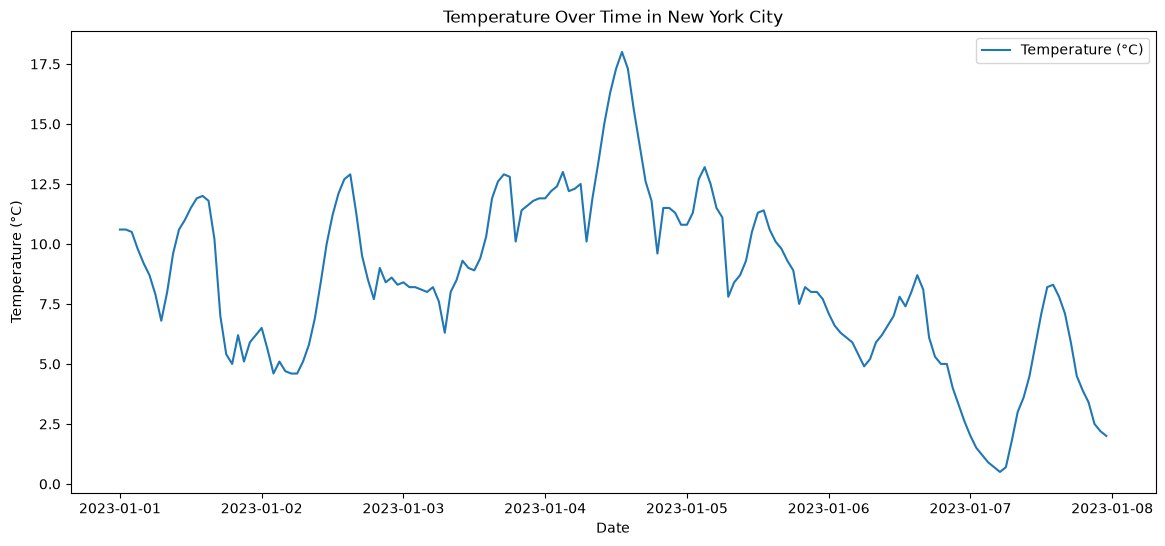

In [13]:
# Plot Temperature Over Time

plt.figure(figsize=(14, 6))
plt.plot(df.index, df['temperature_2m'], label='Temperature (°C)')
plt.title('Temperature Over Time in New York City')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

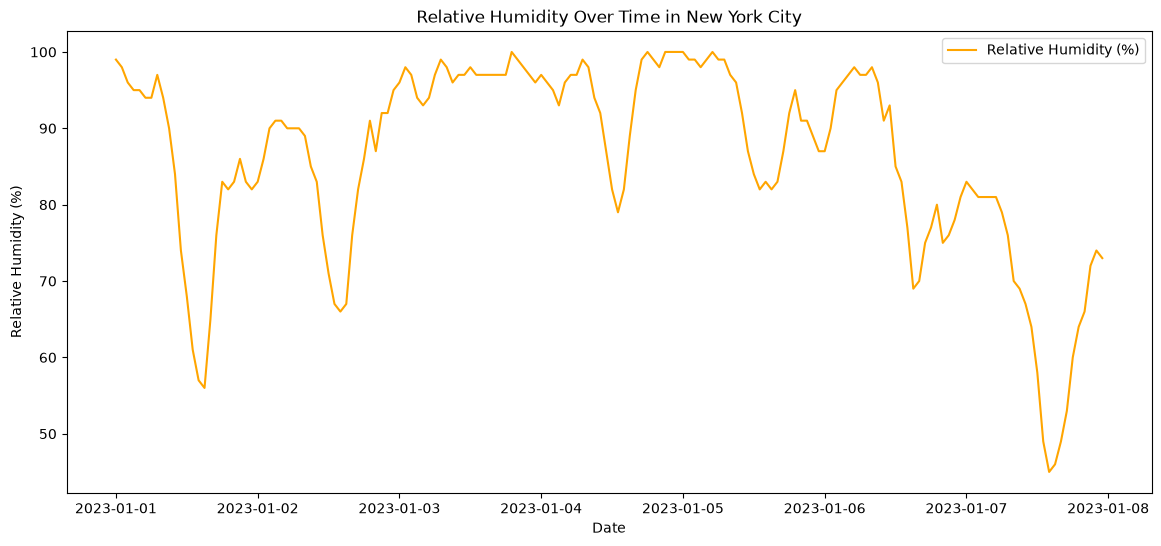

In [14]:
# Plot Relative Humidity Over Time

plt.figure(figsize=(14, 6))
plt.plot(df.index, df['relativehumidity_2m'], color='orange', label='Relative Humidity (%)')
plt.title('Relative Humidity Over Time in New York City')
plt.xlabel('Date')
plt.ylabel('Relative Humidity (%)')
plt.legend()
plt.show()


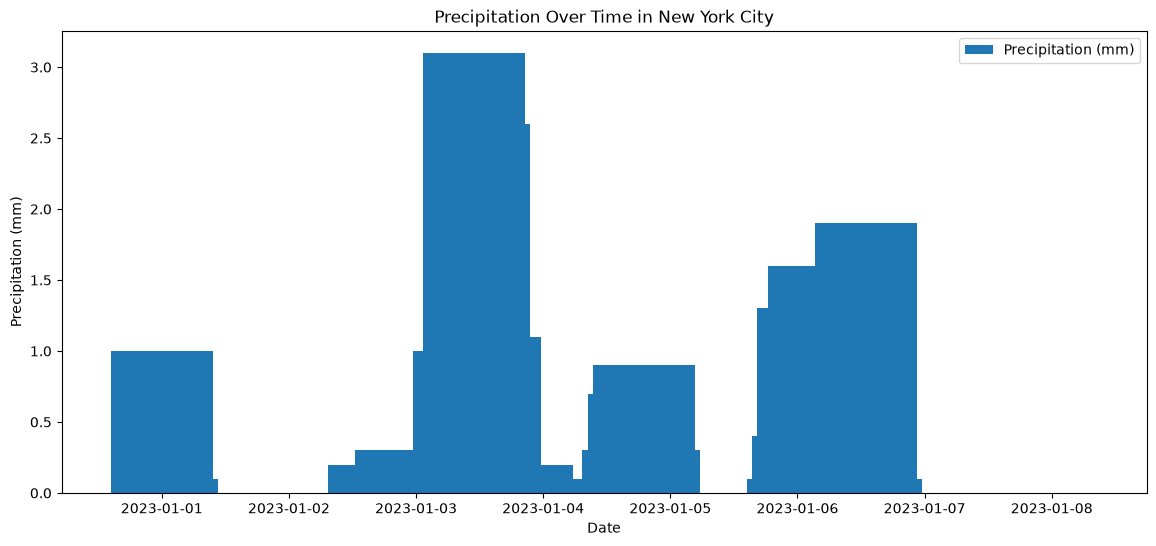

In [15]:
# Plot Precipitation Over Time

plt.figure(figsize=(14, 6))
plt.bar(df.index, df['precipitation'], label='Precipitation (mm)')
plt.title('Precipitation Over Time in New York City')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')
plt.legend()
plt.show()


In [16]:
# Step 6: Correlation Analysis

# Calculate correlation between temperature and humidity
correlation = df['temperature_2m'].corr(df['relativehumidity_2m'])
print(f'Correlation between Temperature and Relative Humidity: {correlation:.2f}')


Correlation between Temperature and Relative Humidity: 0.25


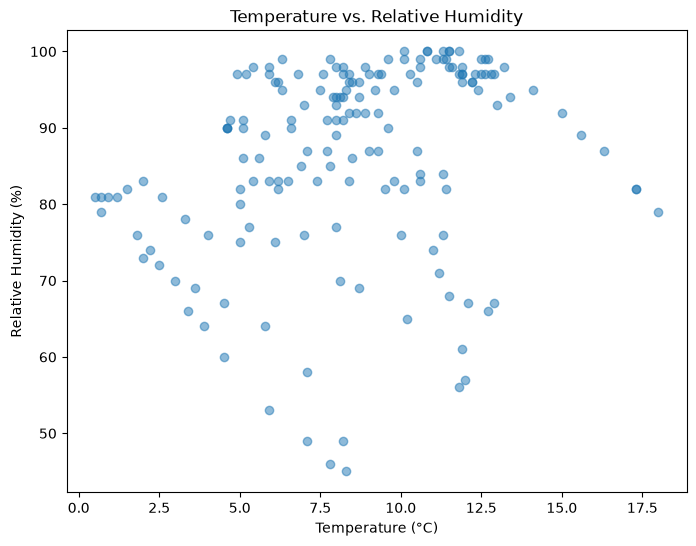

In [17]:
# Scatter Plot of Temperature vs. Relative Humidity

plt.figure(figsize=(8, 6))
plt.scatter(df['temperature_2m'], df['relativehumidity_2m'], alpha=0.5)
plt.title('Temperature vs. Relative Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Relative Humidity (%)')
plt.show()


In [18]:
# Step 7: Resample Data to Daily Averages

daily_avg = df.resample('D').mean()
daily_avg.head()


,temperature_2m,relativehumidity_2m,precipitation
time,,,
2023-01-01,8.812500,83.000000,0.045833
2023-01-02,8.004167,84.000000,0.025000
2023-01-03,9.725000,96.916667,0.391667
2023-01-04,13.108333,94.333333,0.095833
2023-01-05,9.941667,92.125000,0.000000


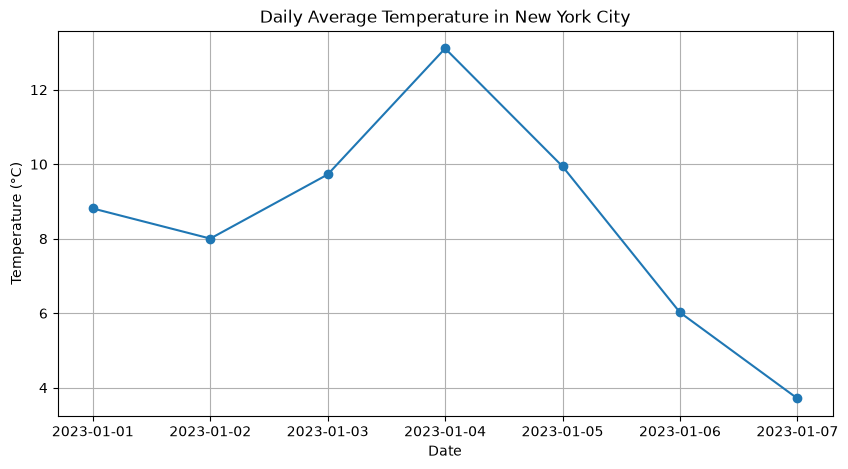

In [19]:
# Plot Daily Average Temperature

plt.figure(figsize=(10, 5))
plt.plot(daily_avg.index, daily_avg['temperature_2m'], marker='o')
plt.title('Daily Average Temperature in New York City')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()


In [20]:
# Step 8: Compare with Another Location (Los Angeles)

# Coordinates for Los Angeles
latitude_la = 34.0522
longitude_la = -118.2437

params_la = {
    'latitude': latitude_la,
    'longitude': longitude_la,
    'start_date': start_date,
    'end_date': end_date,
    'hourly': ','.join(hourly_variables),
    'timezone': 'America/Los_Angeles'
}

response_la = requests.get(base_url, params=params_la)

# Load and clean Los Angeles data
data_la = response_la.json()
hourly_data_la = data_la['hourly']
df_la = pd.DataFrame(hourly_data_la)

df_la['time'] = pd.to_datetime(df_la['time'])
df_la.set_index('time', inplace=True)
df_la = df_la.ffill()  # Forward fill (fillna(method=...) was removed in pandas 3)


In [21]:
# Resample Los Angeles Data to Daily Averages

daily_avg_la = df_la.resample('D').mean()


In [22]:
# Combine DataFrames for Comparison

combined_temp = pd.DataFrame({
    'New York': daily_avg['temperature_2m'],
    'Los Angeles': daily_avg_la['temperature_2m']
})


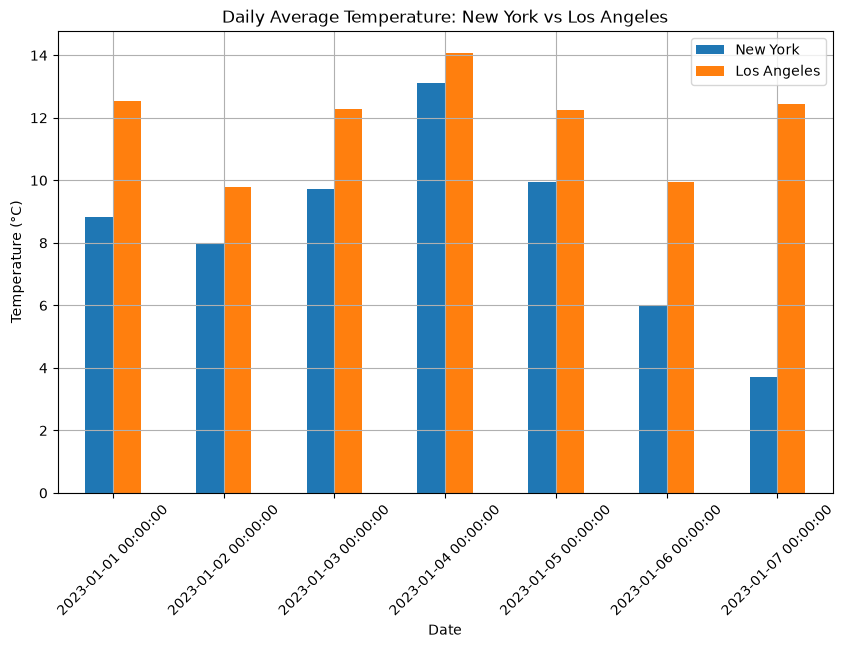

In [23]:
# Plot Comparison of Daily Average Temperature

combined_temp.plot(kind='bar', figsize=(10, 6))
plt.title('Daily Average Temperature: New York vs Los Angeles')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


In [24]:
# Step 9: Advanced Analysis - Temperature Difference

# Calculate Temperature Difference
combined_temp['Temp Difference'] = combined_temp['Los Angeles'] - combined_temp['New York']
combined_temp


,New York,Los Angeles,Temp Difference
time,,,
2023-01-01,8.812500,12.533333,3.720833
2023-01-02,8.004167,9.795833,1.791667
2023-01-03,9.725000,12.270833,2.545833
2023-01-04,13.108333,14.075000,0.966667
2023-01-05,9.941667,12.250000,2.308333
2023-01-06,6.020833,9.962500,3.941667
2023-01-07,3.712500,12.454167,8.741667


In [25]:
# Step 10: Save Data to CSV (Optional)

# Save New York data
df.to_csv('new_york_weather.csv')

# Save Los Angeles data
df_la.to_csv('los_angeles_weather.csv')


## Conclusion

In this exercise, we:

- Accessed and retrieved data from the **Open-Meteo API**.
- Cleaned and preprocessed JSON data using **pandas**.
- Performed exploratory data analysis and visualization.
- Compared weather patterns between **New York City** and **Los Angeles**.

---

**Next Steps**:

- **Extend the Date Range**: Analyze seasonal trends by fetching data over several months.
- **Fetch Additional Variables**: Include wind speed, atmospheric pressure, or other interesting variables.
- **Forecasting**: Use statistical methods or machine learning models to forecast future weather patterns.
- **Global Analysis**: Compare data from other global cities to gain broader insights.


## Exercises for Students

Now it's your turn! Below are some exercises to reinforce what you've learned. Try to complete them without looking at the solutions.

### Exercise: Compare Rainfall Between London and Seattle

- **Objective**: Compare the total weekly rainfall between London and Seattle over a full year.
- **Tasks**:
  1. **Fetch Data**: Retrieve hourly precipitation data for London and Seattle for the year 2022.
     - **London Coordinates**: Latitude `51.5074`, Longitude `-0.1278`
     - **Seattle Coordinates**: Latitude `47.6062`, Longitude `-122.3321`
  2. **Data Cleaning**: Convert the time columns to datetime objects and set them as the index. Handle any missing values.
  3. **Resample Data**: Resample the hourly data to weekly totals.
  4. **Visualization**: Plot the weekly total precipitation for both cities on the same graph.
  5. **Analysis**: Determine which city had more rainfall overall and identify any interesting patterns.

**Note**: Remember to handle any API limitations, such as data availability or rate limits, and to be mindful of the size of the data you're requesting.

### Tips:

- **API Parameters**: Make sure to adjust the parameters like `latitude`, `longitude`, `start_date`, `end_date`, `hourly`, and `timezone` as needed.
- **Error Handling**: Always check if your API requests are successful before proceeding.
- **Data Storage**: Consider saving your DataFrames to CSV files for future analysis.
- **Visualization**: Customize your plots with titles, labels, legends, and gridlines for better readability.

Happy coding!


## My Exercise: Rainfall in London vs. Seattle (2022)

**How to use this section:** fill in each `___`, run the cell, and compare your output with the **Checkpoint** below it. Run the cells in order.

Open-Meteo is free and needs **no API key**, so there is nothing secret to remove before pushing to GitHub.

### Task 1: Fetch the data

Write one helper function that fetches a year of hourly precipitation for any location, checks the request worked, and returns a cleaned DataFrame. Writing it once avoids copying the same code for each city.

If you see `Request failed: 429`, you've hit Open-Meteo's free rate limit (a year of hourly data counts as many requests). Wait a minute and run the cell again.

In [26]:
#Exercise task 1#
#Fill in the request parameters, the success status code, the JSON key that holds the data,
#the pandas function that converts text to dates, and the method that forward-fills gaps
def fetch_precipitation(lat, lon, tz, start='2022-01-01', end='2022-12-31'):
    """Fetch hourly precipitation for one location and return a cleaned DataFrame indexed by time."""
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'hourly': 'precipitation',
        'timezone': tz
    }
    response = requests.get(base_url, params=params, timeout=60)
    if response.status_code != 200:
        raise RuntimeError(f'Request failed: {response.status_code} {response.text[:200]}')

    df_city = pd.DataFrame(response.json()['hourly'])
    df_city['time'] = pd.to_datetime(df_city['time'])
    df_city = df_city.set_index('time')
    print('Missing values:', df_city['precipitation'].isnull().sum())
    df_city = df_city.ffill()  # forward fill any gaps
    return df_city

In [27]:
#Exercise task 2#
#Fetch both cities. Seattle: latitude 47.6062, longitude -122.3321
london = fetch_precipitation(51.5074, -0.1278, 'Europe/London')
seattle = fetch_precipitation(47.6062, -122.3321, 'America/Los_Angeles')
print('London:', london.shape, '| Seattle:', seattle.shape)
london.head()

Missing values: 0
Missing values: 0
London: (8760, 1) | Seattle: (8760, 1)


,precipitation
time,
2022-01-01 00:00:00,0.0
2022-01-01 01:00:00,0.0
2022-01-01 02:00:00,0.0
2022-01-01 03:00:00,0.0
2022-01-01 04:00:00,0.0


**Checkpoint:** `Missing values: 0` printed twice, then `London: (8760, 1) | Seattle: (8760, 1)`. That's 365 days × 24 hours for each city.

### Task 2: Resample to weekly totals

Rainfall adds up, so use the **sum** for each week, not the mean. In pandas, `'W'` means weeks ending on Sunday.

In [28]:
#Exercise task 3#
#Resample each city's hourly precipitation to weekly totals and put them side by side
weekly = pd.DataFrame({
    'London': london['precipitation'].resample('W').sum(),
    'Seattle': seattle['precipitation'].resample('W').sum()
})
print(weekly.shape)
weekly.head()

(53, 2)


,London,Seattle
time,,
2022-01-02,2.2,38.3
2022-01-09,12.9,101.8
2022-01-16,3.1,45.5
2022-01-23,0.0,15.7
2022-01-30,0.4,6.6


**Checkpoint:** `(53, 2)`. There are 53 weeks because 1 January 2022 was a Saturday, so the first "week" ends on Sunday 2 January and holds only two days.

### Task 3: Plot both cities on the same graph

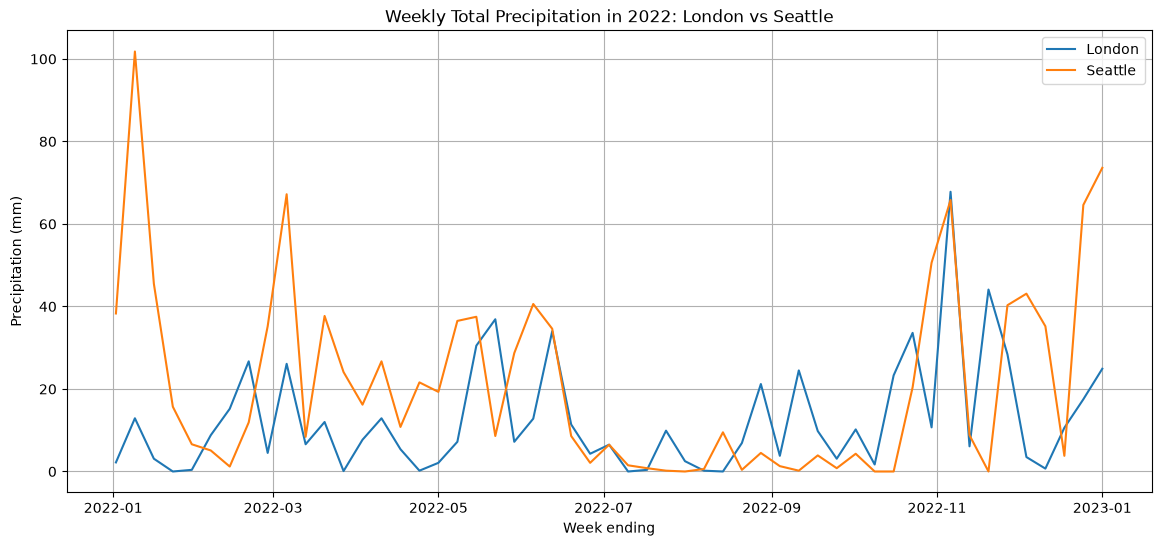

In [29]:
#Exercise task 4#
#Plot weekly rainfall for both cities on one chart, with a title, axis labels, legend and grid
plt.figure(figsize=(14, 6))
plt.plot(weekly.index, weekly['London'], label='London')
plt.plot(weekly.index, weekly['Seattle'], label='Seattle')
plt.title('Weekly Total Precipitation in 2022: London vs Seattle')
plt.xlabel('Week ending')
plt.ylabel('Precipitation (mm)')
plt.legend()
plt.grid(True)
plt.show()

**Checkpoint:** Seattle's line has big peaks in winter (January and November–December) and sits near zero from July to September. London's line is flatter, with its highest weeks in autumn.

### Task 4: Analysis

Work out which city had more rain overall, when each city's wettest week was, and how rainfall compares month by month.

In [30]:
#Exercise task 5#
#Total rainfall for the year, and which city had more
totals = weekly.sum()
print(totals.round(1))
print('Wetter city overall:', totals.idxmax())
print('Seattle had', round(totals['Seattle'] / totals['London'], 2), 'times as much rain as London')

London      663.1
Seattle    1131.2
dtype: float64
Wetter city overall: Seattle
Seattle had 1.71 times as much rain as London


**Checkpoint:** London about 663.1 mm, Seattle about 1,131.2 mm. Seattle was wetter, with about 1.71 times as much rain.

In [31]:
#Exercise task 6#
#The week with the most rain in each city, and how much fell that week
print('Wettest week ending:')
print(weekly.idxmax())
print('Rain that week (mm):')
print(weekly.max().round(1))
print('Weeks where Seattle was wetter than London:', (weekly['Seattle'] > weekly['London']).sum(), 'of', len(weekly))

Wettest week ending:
London    2022-11-06
Seattle   2022-01-09
dtype: datetime64[us]
Rain that week (mm):
London      67.8
Seattle    101.8
dtype: float64
Weeks where Seattle was wetter than London: 31 of 53


**Checkpoint:** Seattle's wettest week ended 9 January (about 101.8 mm). London's ended 6 November (about 67.8 mm). Seattle was wetter in 31 of the 53 weeks.

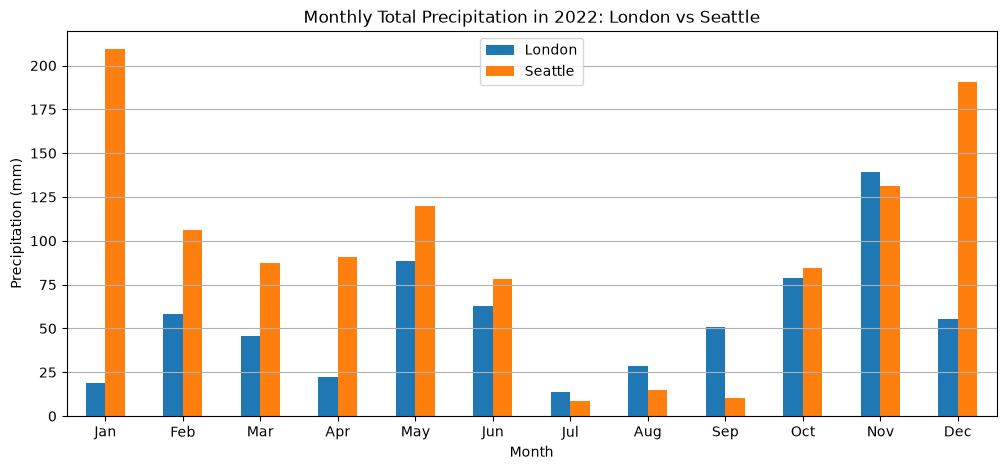

time,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
London,19.0,58.0,46.0,22.0,88.0,63.0,14.0,29.0,51.0,78.0,139.0,56.0
Seattle,209.0,106.0,88.0,91.0,120.0,78.0,8.0,15.0,10.0,84.0,131.0,190.0


In [32]:
#Exercise task 7#
#Monthly totals, to see seasonal patterns more clearly than weekly data
monthly = pd.DataFrame({
    'London': london['precipitation'].resample('ME').sum(),
    'Seattle': seattle['precipitation'].resample('ME').sum()
})
monthly.index = monthly.index.strftime('%b')
monthly.plot(kind='bar', figsize=(12, 5))
plt.title('Monthly Total Precipitation in 2022: London vs Seattle')
plt.xlabel('Month')
plt.ylabel('Precipitation (mm)')
plt.xticks(rotation=0)
plt.grid(True, axis='y')
plt.show()
monthly.round(0).T

**Checkpoint:** Seattle's January (about 209 mm) is the wettest month for either city, followed by its December (about 190 mm). Seattle's July to September are very dry (about 8, 15 and 10 mm), drier than London's in the same months (about 14, 29 and 51 mm). London's wettest month is November (about 139 mm).

`'ME'` means month end. Older pandas used `'M'`, which newer versions no longer accept.

In [33]:
#Exercise task 8#
#Save both cities' hourly data for later use
london.to_csv('london_precipitation_2022.csv')
seattle.to_csv('seattle_precipitation_2022.csv')

### My findings

**Your answer:** Write 3–5 sentences in your own words. Use your outputs above to cover:

* Which city had more rain in 2022, and by how much (total mm and how many times as much)
* When each city's wettest week and month were
* The seasonal pattern: how Seattle's wet winters and dry summers compare with London's more even rainfall
* One thing that surprised you, or a limitation (for example, one year may not be typical, and each city is one point on a map)

Seattle was much wetter than London in 2022. It got about 1,131 mm of rain compared with London’s 663 mm, roughly 1.7 times as much, and it was the wetter city in 31 of the 53 weeks.

Seattle’s wettest week ended on 9 January, with about 102 mm, and its wettest month was January, with about 209 mm. London’s wettest week ended on 6 November, with about 68 mm, and its wettest month was November, with about 139 mm.

The seasonal patterns were very different. Seattle had heavy rain in winter, especially December and January, but was almost dry from July to September (only 8–15 mm a month). London’s rain was spread more evenly across the year, with no month above 140 mm.

What surprised me is that Seattle’s rain came in a few heavy weeks. Despite having far more rain overall, Seattle was wetter than London in only 31 of the 53 weeks. Its single wettest week (about 102 mm) equalled about 15% of London’s rain for the whole year.